# Summary

This analysis explores transactional data from an online retail business to identify revenue drivers, customer behavior, and product performance.

# 0. Setup and Load Data

In [ ]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt


conn = sqlite3.connect("../retail.db")

In [ ]:
pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

,name
0,retail
1,retail_clean
2,retail_clean_dedup
3,retail_final
4,customers
5,products
6,sales


#1 KPI Análisis

## 1.1 TOTAL REVENUE

This metric shows the total revenue generated by the online retail store during the analyzed period.

It helps us understand the overall scale of the business and serves as the baseline for all other KPIs.

In [3]:
query = """
SELECT
ROUND(SUM(quantity * price), 2) AS total_revenue
FROM sales;
"""
print("Total Revenue:", pd.read_sql(query, conn).iloc[0, 0])


Total Revenue: 8886653.14


The total revenue represents the full monetary value generated by all transactions in the dataset.

This KPI is heavily influenced by high-volume orders and repeat customers, indicating that customer retention and order frequency are key drivers of revenue.

# 1.2 TOTAL ORDERS
This KPI shows the total number of unique invoices processed in the dataset.

In [4]:
query = """ 
SELECT
COUNT(DISTINCT invoice_no) AS total_orders
FROM sales;
"""
print("Total Orders:", pd.read_sql(query, conn).iloc[0, 0])

Total Orders: 18532


The number of orders helps measure business activity and demand frequency.

# 1.3 TOTAL CUSTOMERS
This metric represents the number of unique customers who made at least one purchase.

In [5]:
query = """
SELECT
COUNT(DISTINCT customer_id) AS total_customers
FROM customers;
"""
print("Total Customers:", pd.read_sql(query, conn).iloc[0, 0])

Total Customers: 4338


This KPI reflects the size of the active customer base and is key for understanding market reach.

## 1.4 AVERAGE ORDER VALUE
This metric shows the average revenue generated per order.

In [6]:
query = """
SELECT
ROUND(
SUM(quantity * price) /
COUNT(DISTINCT invoice_no),
2
) AS average_order_value
FROM sales;
"""
print("Average Order Value:", pd.read_sql(query, conn).iloc[0, 0])

Average Order Value: 479.53


AOV indicates customer spending behavior. A higher value suggests customers are purchasing more per transaction.

# 1.5 REVENUE BY COUNTRY
This KPI breaks down revenue by geographic region.

In [7]:
query = """
SELECT
c.country,
ROUND(SUM(s.quantity * s.price), 2) AS revenue
FROM sales s
JOIN customers c
ON s.customer_id = c.customer_id
GROUP BY c.country
ORDER BY revenue DESC;
"""
df = pd.read_sql(query, conn)
print("Revenue by Country:")
print(df)

Revenue by Country:
                 country     revenue
0         United Kingdom  7284468.89
1            Netherlands   285446.34
2                   EIRE   265262.46
3                Germany   228678.40
4                 France   208934.31
5              Australia   139843.95
6                  Spain    66470.26
7            Switzerland    57222.85
8                Belgium    47971.21
9                 Sweden    38367.83
10                 Japan    37416.37
11                Norway    36165.44
12              Portugal    33375.84
13               Finland    22546.08
14             Singapore    21279.29
15       Channel Islands    20440.54
16               Denmark    19774.40
17                 Italy    17483.24
18               Austria    16775.84
19                Cyprus    16518.54
20                Poland     7334.65
21                Israel     7215.84
22                Greece     4760.52
23               Iceland     4310.00
24                Canada     3666.38
25                

Revenue is often concentrated in a few countries, showing geographic dependency of the business.

## 1.6 TOP 10 PRODUCTS BY REVENUE
This shows which products generate the most income.

In [8]:
query = """
SELECT
p.product_name,
ROUND(SUM(s.quantity * s.price), 2) AS revenue
FROM sales s
JOIN products p
ON s.product_id = p.product_id
GROUP BY p.product_name
ORDER BY revenue DESC
LIMIT 10;
"""
df = pd.read_sql(query, conn)
print("Top 10 Products by Revenue:")
print(pd.read_sql(query, conn))

Top 10 Products by Revenue:
                         product_name    revenue
0         PAPER CRAFT , LITTLE BIRDIE  168469.60
1            REGENCY CAKESTAND 3 TIER  142264.75
2  WHITE HANGING HEART T-LIGHT HOLDER  100547.45
3  CREAM HANGING HEART T-LIGHT HOLDER  100547.45
4             JUMBO BAG RED RETROSPOT   85040.54
5      MEDIUM CERAMIC TOP STORAGE JAR   81416.73
6                             POSTAGE   77803.96
7                       PARTY BUNTING   68785.23
8       ASSORTED COLOUR BIRD ORNAMENT   56413.03
9                              Manual   53419.93


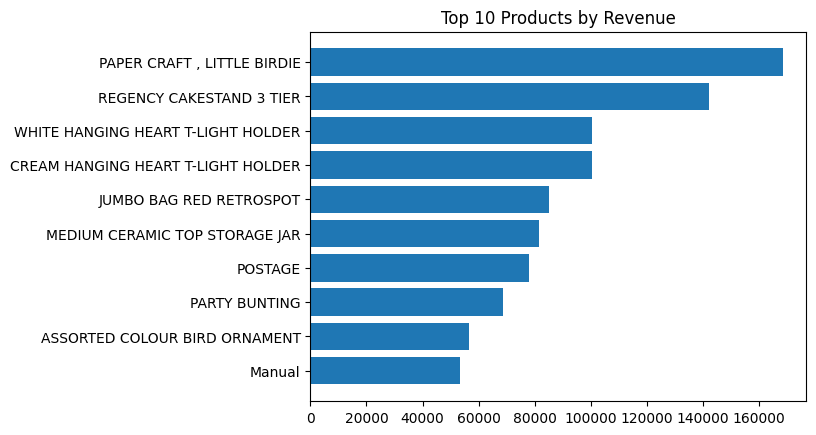

In [9]:
plt.figure()
plt.barh(df["product_name"], df["revenue"])
plt.title("Top 10 Products by Revenue")
plt.gca().invert_yaxis()
plt.show()

A small number of products often contribute disproportionately to total revenue (Pareto effect).

## 1.7 MONTHLY REVENUE TREND


This KPI shows how revenue evolves over time.

In [10]:
query = """
SELECT
strftime('%Y-%m', sale_date) AS month,
ROUND(SUM(quantity * price), 2) AS revenue
FROM sales
GROUP BY month
ORDER BY month;
"""
df=pd.read_sql(query, conn)
print("Monthly Revenue Trend:")
print(df)

Monthly Revenue Trend:
      month     revenue
0   2010-12   570422.73
1   2011-01   568101.31
2   2011-02   446084.92
3   2011-03   594081.76
4   2011-04   468374.33
5   2011-05   677340.30
6   2011-06   660046.05
7   2011-07   598962.90
8   2011-08   644051.04
9   2011-09   950686.30
10  2011-10  1035642.45
11  2011-11  1155668.61
12  2011-12   517190.44


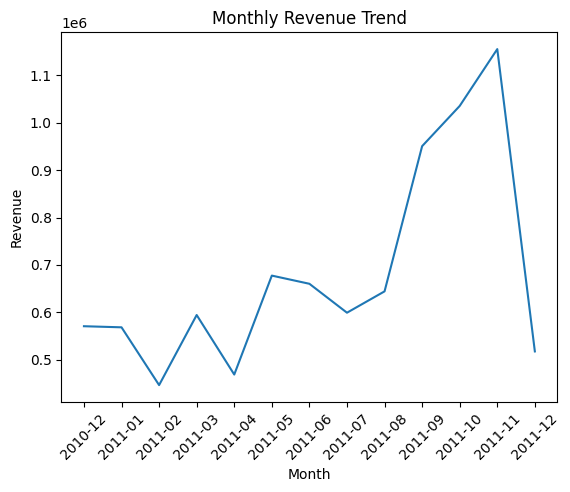

In [11]:
plt.figure()
plt.plot(df["month"], df["revenue"])
plt.xticks(rotation=45)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

Revenue trends help identify seasonality, growth patterns, and demand fluctuations.

## 1.8 BEST CUSTOMERS BY SPENDING
This metric identifies the highest-value customers.

In [12]:
query = """
SELECT
customer_id,
ROUND(SUM(quantity * price), 2) AS total_spent
FROM sales
GROUP BY customer_id
ORDER BY total_spent DESC
LIMIT 10;
"""
df = pd.read_sql(query, conn)
print("Best Customers by Spending:")
print(df)


Best Customers by Spending:
   customer_id  total_spent
0        14646    280206.02
1        18102    259657.30
2        17450    194390.79
3        16446    168472.50
4        14911    143711.17
5        12415    124914.53
6        14156    117210.08
7        17511     91062.38
8        16029     80850.84
9        12346     77183.60


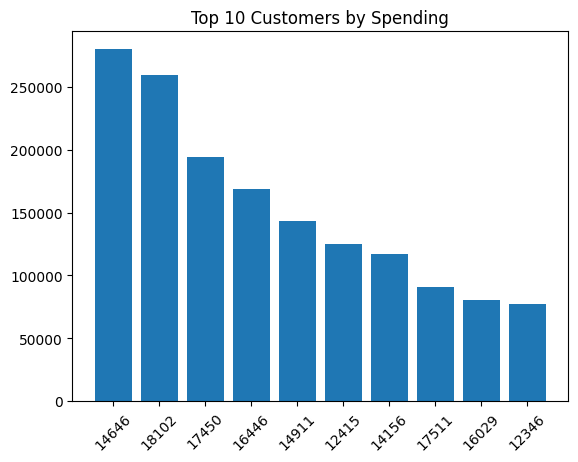

In [13]:
plt.figure()
plt.bar(df["customer_id"].astype(str), df["total_spent"])
plt.title("Top 10 Customers by Spending")
plt.xticks(rotation=45)
plt.show()

A small group of customers typically drives a large share of total revenue (VIP effect).

# 2 Ranking Analysis

This section analyzes the distribution of revenue across customers and products using ranking techniques.

## 2.1 Top customers ranked by total spend

This section identifies the most valuable customers based on total spending.

We use aggregation to calculate total revenue per customer and apply a ranking function to order them from highest to lowest.

In [14]:
query = """
SELECT
    customer_id,
    total_spent,
    RANK() OVER (ORDER BY total_spent DESC) AS rank_position
FROM (
    SELECT
        customer_id,
        SUM(quantity * price) AS total_spent
    FROM sales
    GROUP BY customer_id
);
"""
df = pd.read_sql(query, conn)
print("Customers with Rank:")
print(df)

Customers with Rank:
      customer_id  total_spent  rank_position
0           14646    280206.02              1
1           18102    259657.30              2
2           17450    194390.79              3
3           16446    168472.50              4
4           14911    143711.17              5
...           ...          ...            ...
4333        16878        13.30           4334
4334        17956        12.75           4335
4335        16454         6.90           4336
4336        14792         6.20           4337
4337        16738         3.75           4338

[4338 rows x 3 columns]


Revenue is highly concentrated among a small group of customers.

This suggests a strong dependency on high-value customers, which is typical in retail datasets and aligns with the Pareto principle (80/20 rule).

## 2.2 top products ranked

This analysis identifies which products generate the highest total revenue.

We aggregate sales at product level to evaluate performance across the catalogue.

In [15]:
query = """ 
SELECT
    product_id,
    total_revenue,
    RANK() OVER (ORDER BY total_revenue DESC) AS rank_position
FROM (
    SELECT
        product_id,
        SUM(quantity * price) AS total_revenue
    FROM sales
    GROUP BY product_id
);
"""
df = pd.read_sql(query, conn)   
print("Products with Dense Rank:")
print(df)

Products with Dense Rank:
     product_id  total_revenue  rank_position
0         23843     168469.600              1
1         22423     142264.750              2
2        85123A     100547.450              3
3        85099B      85040.540              4
4         23166      81416.730              5
...         ...            ...            ...
3660      90084          0.850           3661
3661      90104          0.850           3661
3662      21268          0.840           3663
3663      84227          0.420           3664
3664       PADS          0.003           3665

[3665 rows x 3 columns]


A small subset of products generates a disproportionately large share of revenue.

This indicates that product demand is highly concentrated and suggests prioritizing inventory and marketing for these items.

## 2.3 Product Ranking Distribution (Dense Rank)

This section uses DENSE_RANK to group products with similar revenue levels.

It helps identify clusters of product performance rather than strict o

In [16]:
query = """
SELECT
    product_id,
    total_revenue,
    DENSE_RANK() OVER (ORDER BY total_revenue DESC) AS dense_rank_position
FROM (
    SELECT
        product_id,
        SUM(quantity * price) AS total_revenue
    FROM sales
    GROUP BY product_id
);
"""
df = pd.read_sql(query, conn)
print("Products with Dense Rank:")
print(df)


Products with Dense Rank:
     product_id  total_revenue  dense_rank_position
0         23843     168469.600                    1
1         22423     142264.750                    2
2        85123A     100547.450                    3
3        85099B      85040.540                    4
4         23166      81416.730                    5
...         ...            ...                  ...
3660      90084          0.850                 3332
3661      90104          0.850                 3332
3662      21268          0.840                 3333
3663      84227          0.420                 3334
3664       PADS          0.003                 3335

[3665 rows x 3 columns]


Products tend to form revenue clusters rather than a smooth distribution.

This suggests that pricing, demand, or popularity effects create natural groupings in product performance.

## 2.4 Top 10 products by revenue
This query highlights the top 10 best-performing products in terms of total revenue.

In [17]:
query = """
SELECT
    product_id,
    total_revenue
FROM (
    SELECT
        product_id,
        SUM(quantity * price) AS total_revenue
    FROM sales
    GROUP BY product_id
)
ORDER BY total_revenue DESC
LIMIT 10;
"""
df = pd.read_sql(query, conn)
print("Top 10 Products by Revenue:")
print(df)

Top 10 Products by Revenue:
  product_id  total_revenue
0      23843      168469.60
1      22423      142264.75
2     85123A      100547.45
3     85099B       85040.54
4      23166       81416.73
5       POST       77803.96
6      47566       68785.23
7      84879       56413.03
8          M       53419.93
9      23084       51251.24


The top 10 products contribute significantly to overall revenue, reinforcing the importance of focusing on best-selling items for business strategy.

## 2.5 Percentage contribution of each customer to total revenue
This analysis calculates the percentage contribution of each customer to total revenue.

It helps identify how concentrated revenue is across the customer base.

In [18]:
query = """
WITH customer_revenue AS (
    SELECT
        customer_id,
        SUM(quantity * price) AS total_spent
    FROM sales
    GROUP BY customer_id
)

SELECT
    customer_id,
    total_spent,
    ROUND(
        100.0 * total_spent / SUM(total_spent) OVER(),
        2
    ) AS revenue_percentage
FROM customer_revenue
ORDER BY total_spent DESC;
"""
df = pd.read_sql(query, conn)
print("Customer Revenue Percentage:")
print(df)

Customer Revenue Percentage:
      customer_id  total_spent  revenue_percentage
0           14646    280206.02                3.15
1           18102    259657.30                2.92
2           17450    194390.79                2.19
3           16446    168472.50                1.90
4           14911    143711.17                1.62
...           ...          ...                 ...
4333        16878        13.30                0.00
4334        17956        12.75                0.00
4335        16454         6.90                0.00
4336        14792         6.20                0.00
4337        16738         3.75                0.00

[4338 rows x 3 columns]


A small number of customers contribute a large share of total revenue.

This highlights the importance of customer retention strategies and VIP customer management.

# Final Conclusions

- The business generates significant revenue from a relatively small group of high-value customers.
- Revenue is strongly concentrated in a limited number of products, suggesting a Pareto-like distribution.
- Monthly revenue trends show fluctuations over time, indicating possible seasonality effects.
- Ranking analysis highlights the importance of top-performing customers and products in overall business performance.
- SQL-based analysis proved effective for transforming raw transactional data into actionable business insights.